In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [18]:
import numpy as np
import pandas as pd

# Paràmetres del dataset
n_mostres = 1000
n_variables = 6
np.random.seed(42)

X_base = np.random.normal(loc=0.0, scale=1.0, size=(n_mostres, n_variables))

matriu_mescla = np.maximum(
    np.random.uniform(0.75, 1.25, size=(n_variables,n_variables)),
    2*np.eye(n_variables)) -1 

# 3. Aplicar la mescla per introduir petites correlacions creuades
X_sintetic = np.dot(X_base, matriu_mescla)

# Convertir a DataFrame de Pandas
noms_columnes = [f"Var_{i+1}" for i in range(n_variables)]
df = pd.DataFrame(X_sintetic, columns=noms_columnes)

# 4. Comprovació: Mostrar la matriu de correlació
print("Matriu de Correlació:")
print(df.corr().round(2))

Matriu de Correlació:
       Var_1  Var_2  Var_3  Var_4  Var_5  Var_6
Var_1   1.00  -0.19   0.10   0.10   0.07  -0.24
Var_2  -0.19   1.00  -0.03   0.05   0.43  -0.28
Var_3   0.10  -0.03   1.00   0.25   0.04   0.07
Var_4   0.10   0.05   0.25   1.00  -0.29  -0.05
Var_5   0.07   0.43   0.04  -0.29   1.00   0.01
Var_6  -0.24  -0.28   0.07  -0.05   0.01   1.00


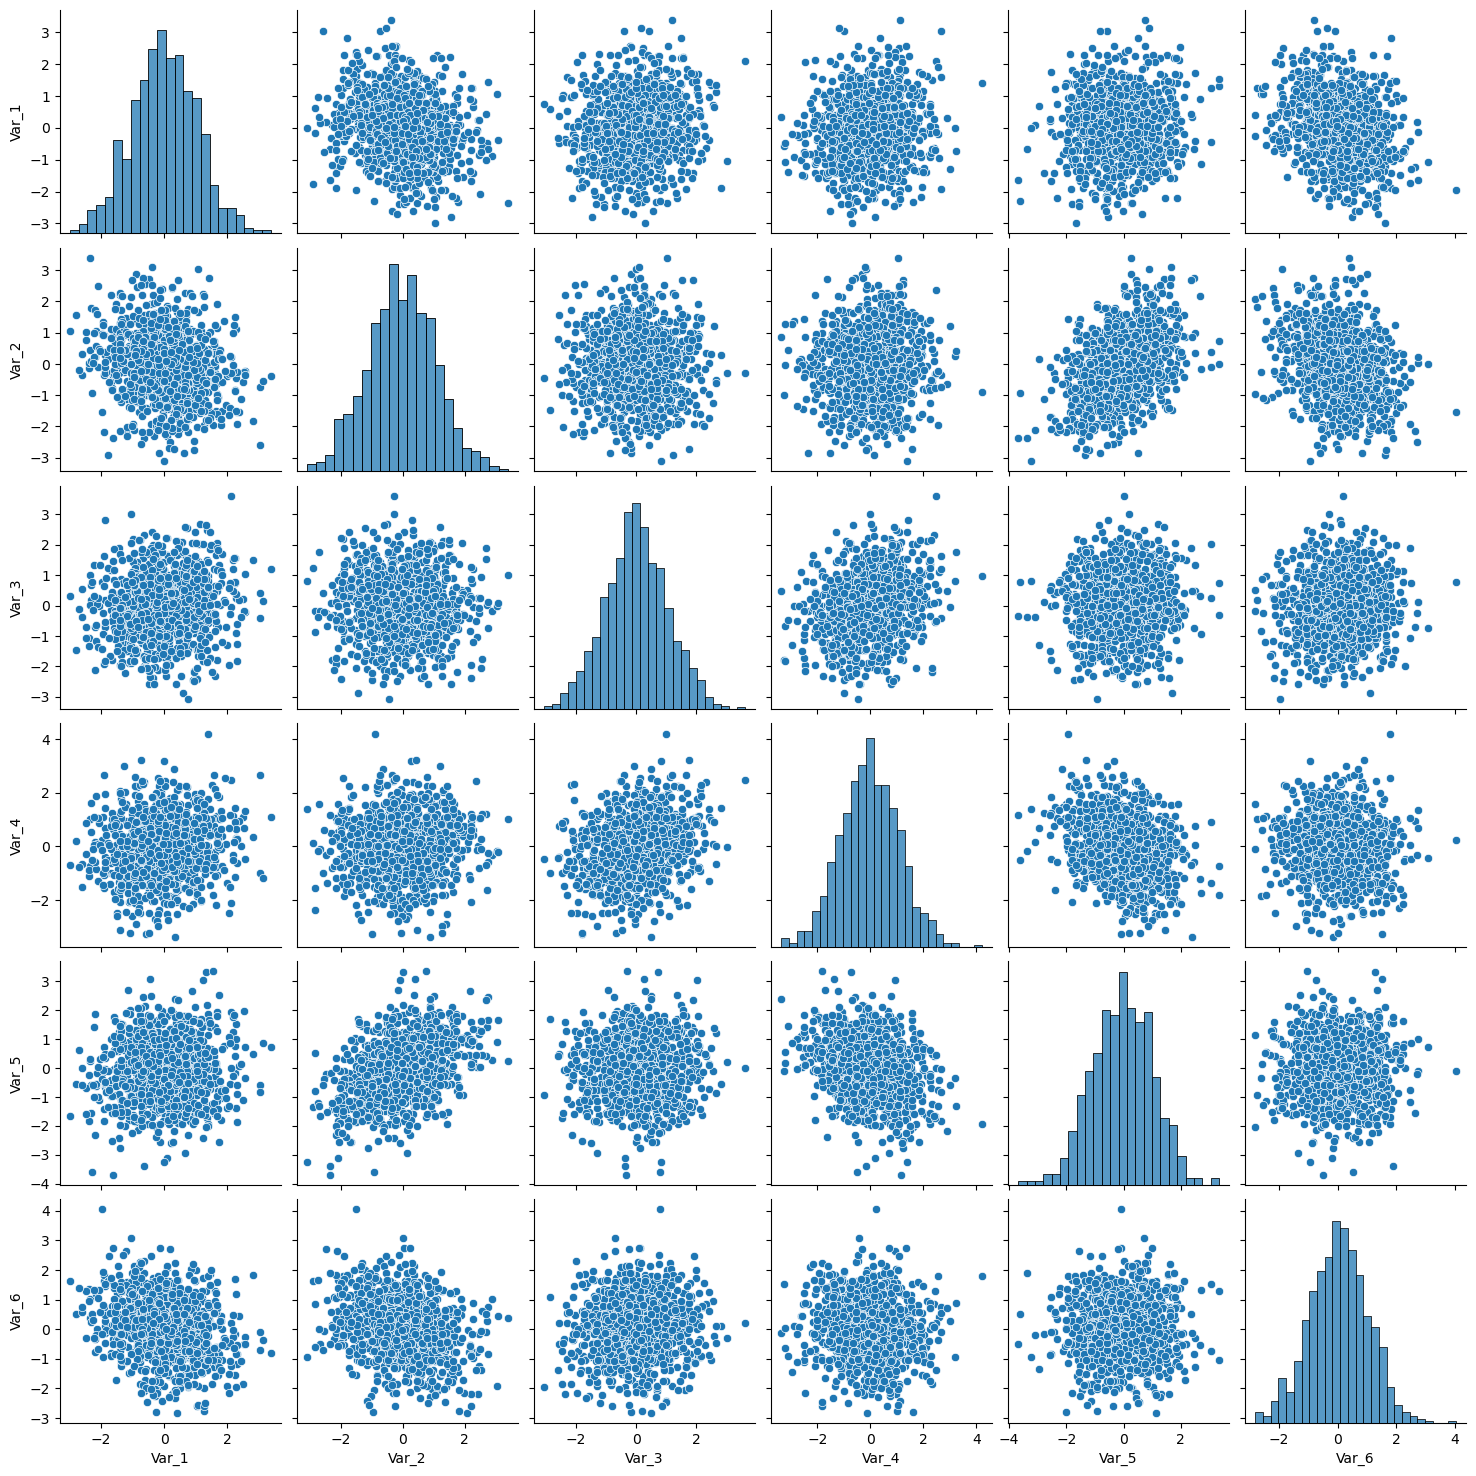

In [19]:
sns.pairplot(data=df)

$$y = 2\text{Var}_1 + \text{Var}_2^2 - \text{Var}_3^3 + 5\sin(\text{Var}_4) - \sin(\text{Var}_5)\text{Var}_5 + \text{Var}_6$$

In [20]:
y = 2 * df["Var_1"] + df["Var_2"]**2 - df["Var_3"]**3 + 5 * np.sin(df["Var_4"]) - np.sin(df["Var_5"])*df["Var_5"] + df["Var_6"]

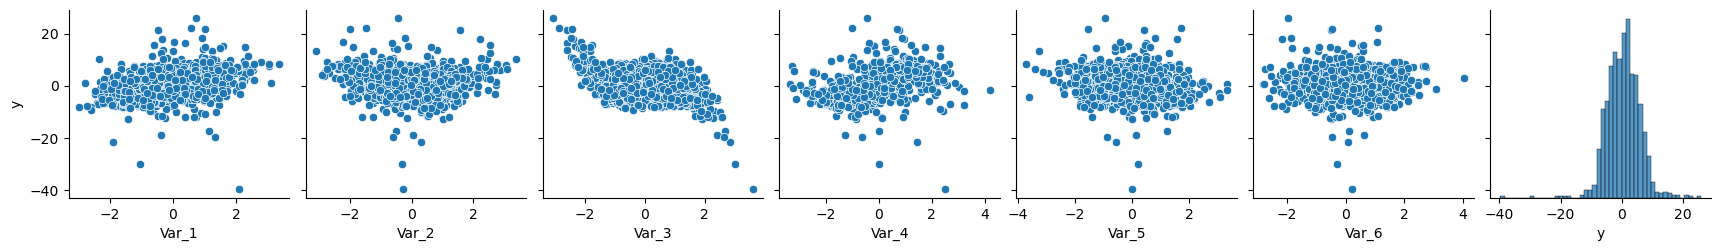

In [22]:
df_final = df.copy()
df_final["y"] = y
sns.pairplot(data=df_final, y_vars="y" )

In [37]:
corr = df_final.corr()
corr.loc["y"]

Var_1    0.335503
Var_2   -0.076226
Var_3   -0.396266
Var_4    0.435426
Var_5   -0.158332
Var_6   -0.000508
y        1.000000
Name: y, dtype: float64

<Axes: >

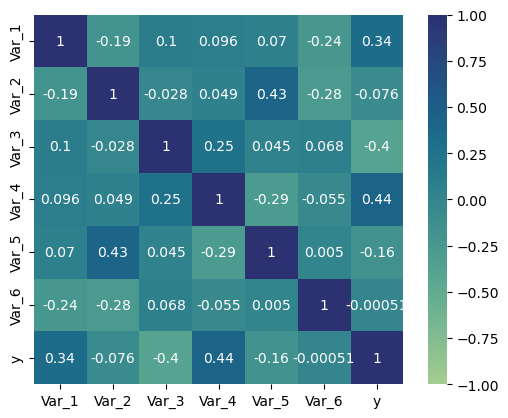

In [39]:
sns.heatmap(corr, square=True, annot=True, vmin=-1, vmax=1, cmap="crest")

> Fes un entrenament amb regressió lineal separant train de test i avalua el R²

> Fes la transformació polinòmica i avalua si el resultat millora a la lineal. 

> Imprimeix l'equació final filtrant per aquells coeficients que superen una certa influència. Observa si es pareix a l'original. 